In [1]:
import pandas as pd
import numpy as np
import os
from scipy import stats

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [3]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    log_loss,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_curve,
    auc
)

In [5]:
os.getcwd()
os.chdir('a:\\Dominic\\My Projects\\Home Credit')

In [10]:
files = [f for f in os.listdir('src/intermediate') if f.endswith('.parquet')]
files.remove('prev_loan_data_processed.parquet'
             )
dataframes = {}
for parquet_file in files:
    file_path = os.path.join('src/intermediate', parquet_file)
    key = os.path.splitext(parquet_file)[0]
    dataframes[key] = pd.read_parquet(file_path)
    print(f"Loaded {key}: {dataframes[key].shape}")

Loaded application_train_data_processed: (307511, 141)
Loaded bureau_processed: (305811, 26)
Loaded creditcard_processed: (86905, 374)
Loaded payment_installments_processed: (291643, 72)
Loaded posdata_processed: (289444, 29)


In [11]:
# Join all loaded tables into one combined DataFrame
join_keys = ['SK_ID_CURR']
print(f"Using join key(s): {join_keys}")

combined_df = None
for name, df in dataframes.items():
    if combined_df is None:
        combined_df = df.copy()
    else:
        combined_df = combined_df.merge(df, how='left', on=join_keys, suffixes=(None, f'_{name}'))
    print(f"After merging {name}: {combined_df.shape}")

print(f"Final combined DataFrame shape: {combined_df.shape}")

Using join key(s): ['SK_ID_CURR']
After merging application_train_data_processed: (307511, 141)
After merging bureau_processed: (307511, 167)
After merging creditcard_processed: (307511, 540)
After merging payment_installments_processed: (307511, 611)
After merging posdata_processed: (307511, 639)
Final combined DataFrame shape: (307511, 639)


In [12]:
del df, dataframes

In [13]:
numeric_selection_metrics_full_df = pd.read_excel('src\\Variable-Selection\\numeric_selection_metrics_full_df_2.xlsx')

In [14]:
feature_cols = numeric_selection_metrics_full_df.loc[numeric_selection_metrics_full_df['points']>1,'variable']

In [15]:
cat_cols = combined_df.select_dtypes(include=['object']).columns.to_list()
cat_cols.remove('SK_ID_CURR')

In [16]:
feature_cols = feature_cols.tolist() + cat_cols

In [17]:
feature_cols

['AMT_BALANCE_3Y_AVG',
 'AMT_DRAWINGS_ATM_CURRENT_3Y_AVG',
 'AMT_DRAWINGS_CURRENT_3Y_AVG',
 'AMT_DRAWINGS_POS_CURRENT_3Y_AVG',
 'AMT_INST_MIN_REGULARITY_3Y_AVG',
 'AMT_PAYMENT_CURRENT_3Y_AVG',
 'AMT_PAYMENT_TOTAL_CURRENT_3Y_AVG',
 'AMT_RECEIVABLE_PRINCIPAL_3Y_AVG',
 'AMT_RECIVABLE_3Y_AVG',
 'AMT_TOTAL_RECEIVABLE_3Y_AVG',
 'CNT_DRAWINGS_ATM_CURRENT_3Y_AVG',
 'CNT_DRAWINGS_CURRENT_3Y_AVG',
 'CNT_DRAWINGS_OTHER_CURRENT_3Y_AVG',
 'CNT_DRAWINGS_POS_CURRENT_3Y_AVG',
 'UTILIZATION_RATIO_3Y_AVG',
 'DRAWING_TO_PYMNT_RATIO_3Y_AVG',
 'INT_COVERAGE_RATIO_3Y_AVG',
 'POS_DRAWING_AMT_RATIO_3Y_AVG',
 'ATM_DRAWING_AMT_RATIO_3Y_AVG',
 'POS_DRAWING_CNT_RATIO_3Y_AVG',
 'ATM_DRAWING_CNT_RATIO_3Y_AVG',
 'ISNULL_DRAWINGS_CURRENT_FLAG_3Y_AVG',
 'AMT_CREDIT_LIMIT_ACTUAL_YOY_PCT_CHANGE_3Y_AVG',
 'AMT_DRAWINGS_CURRENT_YOY_PCT_CHANGE_3Y_AVG',
 'AMT_RECEIVABLE_PRINCIPAL_YOY_PCT_CHANGE_3Y_AVG',
 'POS_DRAWING_CNT_RATIO_YOY_PCT_CHANGE_3Y_AVG',
 'CNT_DRAWINGS_ATM_CURRENT_YOY_ABS_CHANGE_3Y_AVG',
 'AMT_BALANCE_3Y_MAX',


In [18]:
for col in cat_cols:
    combined_df[col] = combined_df[col].astype('category')

In [19]:
X = combined_df[feature_cols]
y = combined_df['TARGET']

In [20]:
del combined_df

In [21]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, log_loss
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials, space_eval

In [30]:
# --- 0. Prepare Sample Data ---
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=1994, stratify=y)

In [23]:
X_train.shape

(246008, 358)

In [24]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import xgboost as xgb

In [35]:
space = {
    # 1. Core Tree Structure (Synced up)
    # We expand num_leaves so the model can actually utilize deeper trees if needed.
    'num_leaves': hp.quniform('num_leaves', 20, 150, 1),
    'max_depth': hp.quniform('max_depth', 4, 12, 1), 
    
    # 2. Learning Rate & Boosting Iterations
    'learning_rate': hp.loguniform('learning_rate', np.log(0.01), np.log(0.2)),
    # Recommendation: Set n_estimators high (e.g., 1000) and use early_stopping 
    # instead of tuning it as a hard boundary here. If tuning, expand the range:
    'n_estimators': hp.quniform('n_estimators', 100, 1000, 10),
    
    # 3. Row & Feature Sampling (Great for 358 features)
    'subsample': hp.uniform('subsample', 0.6, 1.0),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.4, 1.0), # Lowered to 0.4 to combat feature noise
    
    # 4. Aggressive Regularization (Expanded for wide datasets)
    'reg_alpha': hp.loguniform('reg_alpha', np.log(1e-3), np.log(100.0)),
    'reg_lambda': hp.loguniform('reg_lambda', np.log(1e-3), np.log(100.0)),
    
    # 5. The Overfitting Savior for data with many columns
    # Prevents creating leaves with only a handful of samples
    'min_child_samples': hp.quniform('min_child_samples', 20, 500, 10)
}

In [ ]:
# --- 1. Define the Objective Function ---
def objective(params):
    """
    The objective function for Hyperopt to minimize.
    It trains a LightGBM model and returns the validation loss.
    """
    # Copy the dictionary so we don't accidentally mutate the original search space
    current_params = params.copy()
    # Hyperopt sends integer parameters as floats, so we need to convert them
    current_params['num_leaves'] = int(current_params['num_leaves'])
    current_params['max_depth'] = int(current_params['max_depth'])
    current_params['n_estimators'] = int(current_params['n_estimators'])
    current_params['min_child_samples'] = int(current_params['min_child_samples'])
    
    # 2. Setup Manual Cross-Validation for Early Stopping
    # cross_val_score doesn't natively support LightGBM early stopping callbacks,
    # so manual folding is much faster and prevents overfitting.
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    auc_scores = []
    
    # Converting to numpy arrays for safer indexing
    X_arr = np.array(X_train)
    y_arr = np.array(y_train)

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]
    
        # Initialize model with global controls
        model = lgb.LGBMClassifier(
            objective='binary',
            boosting_type='goss',
            max_bin=63,  # Default is 255, but can be tuned for high-cardinality features
            device='cpu',
            seed=42,
            n_jobs=-1,  # Use ALL cores for training a single tree (Fastest approach)
            verbose=-1,
            **current_params
        )
        
        # Train with early stopping to save massive amounts of time
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_va, y_va)],
            callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
        )
        
        # Predict probabilities for the positive class
        preds = model.predict_proba(X_va)[:, 1]
        auc = roc_auc_score(y_va, preds)
        auc_scores.append(auc)
        
    mean_auc = np.mean(auc_scores)
    
    # Hyperopt MINIMIZES the return value, so we negate ROC-AUC
    return {'loss': -mean_auc, 'status': 'ok'}

In [ ]:
# The Trials object stores the history of the search
trials = Trials()

# Run the optimization
best = fmin(
    fn=objective,          # The function to minimize
    space=space,           # The hyperparameter space
    algo=tpe.suggest,      # The search algorithm (TPE)
    max_evals=150,         # The number of trials to run
    trials=trials          # The object to store the results
)

print("\n--- Hyperopt Search Complete ---")

100%|██████████| 150/150 [10:42:05<00:00, 256.84s/trial, best loss: -0.7902199197979357]   

--- Hyperopt Search Complete ---
Best hyperparameters found:


NameError: name 'space_eval' is not defined

In [53]:
import json

In [ ]:
print("Best hyperparameters found:")
resolved_best = space_eval(space, best)

# Convert all float values back to clean integers for your final model
resolved_best['num_leaves'] = int(resolved_best['num_leaves'])
resolved_best['max_depth'] = int(resolved_best['max_depth'])
resolved_best['n_estimators'] = int(resolved_best['n_estimators'])
resolved_best['min_child_samples'] = int(resolved_best['min_child_samples'])

# Safely remove subsample if you are using GOSS
if 'subsample' in resolved_best:
    del resolved_best['subsample']

print(json.dumps(resolved_best, indent=4))

{
    "colsample_bytree": 0.49843120969470817,
    "learning_rate": 0.021523244311830798,
    "max_depth": 8,
    "min_child_samples": 450,
    "n_estimators": 780,
    "num_leaves": 88,
    "reg_alpha": 0.03572601757164547,
    "reg_lambda": 0.023836232805870886
}


In [29]:
del X_train, y_train, X_val, y_val

In [25]:
resolved_best = {
    "colsample_bytree": 0.49843120969470817,
    "learning_rate": 0.021523244311830798,
    "max_depth": 8,
    "min_child_samples": 450,
    "n_estimators": 780,
    "num_leaves": 88,
    "reg_alpha": 0.03572601757164547,
    "reg_lambda": 0.023836232805870886
}

In [ ]:
trials_df = pd.DataFrame(trials.results)
trials_df['auc'] = -trials_df['loss']
trials_history = pd.DataFrame(trials.trials)

In [26]:
from lightgbm.callback import early_stopping, log_evaluation
from sklearn.metrics import f1_score

In [27]:
# Define the custom evaluation function for F1-score
def lgb_f1_score(y_true, y_pred):
    """
    Custom F1 score metric for LightGBM.
    """
    # y_pred will be probabilities, so we need to convert them to 0/1 predictions
    # using a standard 0.5 threshold.
    precision, recall, thresholds = precision_recall_curve(y_true, y_pred)

    # Calculate F1-score for each threshold
    # Note: We add a small epsilon to avoid division by zero
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

    # Find the threshold that maximizes the F1-score
    best_f1_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_f1_idx]
    best_f1_score = f1_scores[best_f1_idx]

    y_pred_binary = (y_pred > best_threshold).astype(int)
    
    # Calculate F1 score
    score = f1_score(y_true, y_pred_binary)
    
    # The return format is (metric_name, metric_value, is_higher_better)
    return 'f1', score, True

In [37]:
# 1. Create a single train/validation split
X_train_final, X_val_final, y_train_final, y_val_final = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=1994
)

# 2. Initialize the model with your exact resolved_best parameters
# Ensure 'device' is set to 'cuda' so it runs fast!
final_model = lgb.LGBMClassifier(
    objective='binary',
    boosting_type='goss',
 #   device='gpu',
 #   gpu_platform_id = 0,  # Tells it to use the primary OpenCL platform
 #   gpu_device_id = 0,    # Tells it to use the primary GPU
 #   verbosity = 2,           # Verbose mode will print the GPU detection logs
    seed=42,
    verbose=-1,
    **resolved_best  # Unpacks your optimized hyperparameter dictionary
)

In [38]:
# 3. Train the model
print("Training the final optimized model...")
final_model.fit(
    X_train_final, y_train_final,
    eval_set=[(X_val_final, y_val_final)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=True)] 
)

# Evaluate on test set
y_pred_proba = final_model.predict_proba(X_val_final)[:, 1]
test_auc = roc_auc_score(y_val_final, y_pred_proba)
print(f"Test AUC: {test_auc:.4f}")

Training the final optimized model...
Training until validation scores don't improve for 50 rounds
Did not meet early stopping. Best iteration is:
[777]	valid_0's binary_logloss: 0.237887
Test AUC: 0.7836


In [39]:
# --- 4. Find the Optimal Threshold from the Precision-Recall Curve ---
# Get precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_val_final, y_pred_proba)

# Calculate F1-score for each threshold
# Note: We add a small epsilon to avoid division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# Find the threshold that maximizes the F1-score
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score = f1_scores[best_f1_idx]

print(f"\n--- Finding the Optimal Threshold ---")
print(f"Best Threshold found: {best_threshold:.4f}")
print(f"F1-Score at this threshold: {best_f1_score:.4f}\n")

# Evaluate performance at the new, optimal threshold
y_pred_optimal = (y_pred_proba >= best_threshold) * 1

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val_final, y_pred_optimal))


--- Finding the Optimal Threshold ---
Best Threshold found: 0.1664
F1-Score at this threshold: 0.3399

--- Performance at Optimal Threshold (0.17) ---
              precision    recall  f1-score   support

           0       0.95      0.90      0.92     42403
           1       0.28      0.44      0.34      3724

    accuracy                           0.86     46127
   macro avg       0.61      0.67      0.63     46127
weighted avg       0.89      0.86      0.88     46127



In [40]:
# 1. Create your importance dataframe
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': final_model.feature_importances_
}).sort_values(by='importance', ascending=False).reset_index(drop=True)

# 2. Calculate the percentage contribution and cumulative sum
importance_df['percentage'] = importance_df['importance'] / importance_df['importance'].sum()
importance_df['cumulative_importance'] = importance_df['percentage'].cumsum()

# 3. Filter to find features that make up 95% of the total model split decisions
significant_features = importance_df[importance_df['cumulative_importance'] <= 0.95]['feature'].tolist()

print(f"Original features: {len(X_train.columns)}")
print(f"Features needed to reach 95% importance: {len(significant_features)}")

Original features: 358
Features needed to reach 95% importance: 150


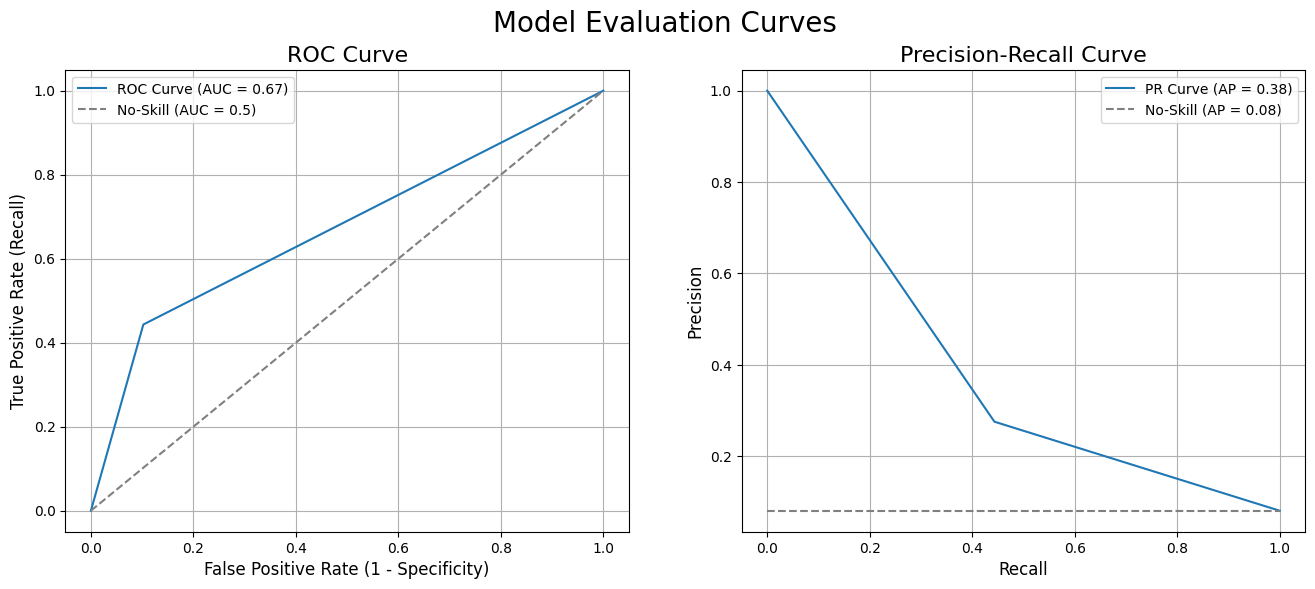

In [41]:
# For ROC Curve
y_pred_proba = y_pred_optimal
fpr, tpr, roc_thresholds = roc_curve(y_val_final, y_pred_proba)
roc_auc = roc_auc_score(y_val_final, y_pred_proba)

# For Precision-Recall Curve
precision, recall, pr_thresholds = precision_recall_curve(y_val_final, y_pred_proba)
pr_auc = auc(recall, precision)

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: ROC Curve ---
ax1.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
ax1.plot([0, 1], [0, 1], linestyle='--', color='gray', label='No-Skill (AUC = 0.5)')
ax1.set_title('ROC Curve', fontsize=16)
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax1.set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax1.legend()
ax1.grid(True)

# --- Plot 2: Precision-Recall Curve ---
ax2.plot(recall, precision, label=f'PR Curve (AP = {pr_auc:.2f})')
no_skill = len(y_val_final[y_val_final==1]) / len(y_val_final)
ax2.plot([0, 1], [no_skill, no_skill], linestyle='--', color='gray', label=f'No-Skill (AP = {no_skill:.2f})')
ax2.set_title('Precision-Recall Curve', fontsize=16)
ax2.set_xlabel('Recall', fontsize=12)
ax2.set_ylabel('Precision', fontsize=12)
ax2.legend()
ax2.grid(True)

# Add a main title and show the plot
fig.suptitle('Model Evaluation Curves', fontsize=20)
plt.show()

In [43]:
# 4. Calculate and print metrics
print(f"Accuracy: {accuracy_score(y_val_final, y_pred_optimal):.4f} (Can be misleading on imbalanced data)\n")

# Metrics that require probabilities
print(f"AUC Score: {roc_auc_score(y_val_final, y_pred_optimal):.4f}")
print(f"Log Loss: {log_loss(y_val_final, y_pred_optimal):.4f}\n")

# Metrics that require binary labels
print(f"Precision: {precision_score(y_val_final, y_pred_optimal):.4f}")
print(f"Recall (Sensitivity): {recall_score(y_val_final, y_pred_optimal):.4f}")
print(f"F1-Score: {f1_score(y_val_final, y_pred_optimal):.4f}\n")

Accuracy: 0.8610 (Can be misleading on imbalanced data)

AUC Score: 0.6705
Log Loss: 5.0111

Precision: 0.2756
Recall (Sensitivity): 0.4433
F1-Score: 0.3399



# Gaussian

In [45]:
from sklearn.naive_bayes import GaussianNB

# 1. Initialize the model
nb = GaussianNB()

# 2. Train the model
print("Training Naive Bayes...")
nb.fit(X_train_final, y_train_final)

# 3. Make predictions and evaluate
y_pred_proba = nb.predict_proba(X_val_final)[:, 1]
auc = roc_auc_score(y_val_final, y_pred_proba)

print(f"\nNaive Bayes AUC Score: {auc:.4f}")

Training Naive Bayes...


ValueError: Input contains NaN

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [ ]:
# Handle missing values
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.20, random_state=17,stratify=y)

# Fit logistic regression model
model = LogisticRegression(random_state=124, max_iter=10000, penalty='l1', solver='liblinear', C=0.1)
model.fit(X_train, y_train)

# Create DataFrame with coefficients
coef_df = pd.DataFrame({'variable': feature_cols, 'coef': model.coef_[0]})

ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [49]:
y_pred_proba = model.predict_proba(X_val)[:, 1]  # This will give the predicted probabilities for the validation set

In [50]:
# --- 4. Find the Optimal Threshold from the Precision-Recall Curve ---
# Get precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_val, y_pred_proba)

# Calculate F1-score for each threshold
# Note: We add a small epsilon to avoid division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# Find the threshold that maximizes the F1-score
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score = f1_scores[best_f1_idx]

print(f"\n--- Finding the Optimal Threshold ---")
print(f"Best Threshold found: {best_threshold:.4f}")
print(f"F1-Score at this threshold: {best_f1_score:.4f}\n")

# Evaluate performance at the new, optimal threshold
y_pred_optimal = (y_pred_proba >= best_threshold) * 1

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val, y_pred_optimal))


--- Finding the Optimal Threshold ---
Best Threshold found: 0.1335
F1-Score at this threshold: 0.2444

--- Performance at Optimal Threshold (0.13) ---
              precision    recall  f1-score   support

           0       0.93      0.86      0.90     15973
           1       0.19      0.34      0.24      1518

    accuracy                           0.82     17491
   macro avg       0.56      0.60      0.57     17491
weighted avg       0.87      0.82      0.84     17491



In [51]:
roc_auc = roc_auc_score(y_val, y_pred_proba)
print(f"ROC AUC Score: {roc_auc:.4f}")

ROC AUC Score: 0.6402


In [30]:
# --- 1. Define the Objective Function ---
def objective(params):
    """
    The objective function for Hyperopt to minimize.
    It trains a LightGBM model and returns the validation loss.
    """
    # Hyperopt sends integer parameters as floats, so we need to convert them
    params['num_leaves'] = int(params['num_leaves'])
    params['max_depth'] = int(params['max_depth'])
    params['n_estimators'] = int(params['n_estimators'])
    
    # Initialize the XGBoost model
    model = xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='auc',
        random_state=42,
        use_label_encoder=False,
        n_jobs=-1,
        **params  # Unpack the dictionary of hyperparameters
    )

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    mean_auc = cross_val_score(model, X_train, y_train,
                               scoring='roc_auc', cv=cv, n_jobs=-1).mean()

    # Return the standard Hyperopt dictionary format
    return {'loss': -mean_auc, 'status': STATUS_OK}

In [31]:
# --- 3. Run the Optimization ---
# The Trials object will store the history of the search
trials = Trials()

# fmin is the optimization function
best_params = fmin(
    fn=objective,          # The function to minimize
    space=space,           # The hyperparameter space
    algo=tpe.suggest,      # The search algorithm (Tree-of-Parzen-Estimators)
    max_evals=150,         # The number of trials to run
    trials=trials          # The object to store the results
)

print("\n--- Hyperopt Search Complete ---")
print("Best hyperparameters found:")
# Convert float values back to int for integer parameters
best_params['n_estimators'] = int(best_params['n_estimators'])
best_params['num_leaves'] = int(best_params['num_leaves'])
best_params['max_depth'] = int(best_params['max_depth'])
print(best_params)

100%|██████████| 150/150 [30:16<00:00, 12.11s/trial, best loss: -0.6650535181582229]

--- Hyperopt Search Complete ---
Best hyperparameters found:
{'colsample_bytree': np.float64(0.8714610650925534), 'max_depth': 3, 'n_estimators': 50, 'num_leaves': 57, 'reg_alpha': np.float64(0.4749466419949838), 'reg_lambda': np.float64(0.14089776932425035)}


In [56]:
best_params  = {
    'colsample_bytree': np.float64(0.8714610650925534), 
    'max_depth': 3, 
    'n_estimators': 50, 
    'num_leaves': 57, 
    'reg_alpha': np.float64(0.4749466419949838), 
    'reg_lambda': np.float64(0.14089776932425035)
    }

In [57]:
# 1. Initialize the XGBoost model
# 'eval_metric' is set to avoid a future deprecation warning.
xgboost_model = xgb.XGBClassifier(
    random_state=42,
    eval_metric='auc',
    **best_params
)

# 2. Train the model
print("Training XGBoost...")
xgboost_model.fit(X_train, y_train)

# 3. Make predictions and evaluate
y_pred_proba = xgboost_model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred_proba)

print(f"\nXGBoost AUC Score: {auc:.4f}")

Training XGBoost...


a:\Dominic\My Projects\Home Credit\project_env\Lib\site-packages\xgboost\training.py:183: UserWarning: [10:52:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "num_leaves" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



XGBoost AUC Score: 0.6526


In [58]:
# --- 4. Find the Optimal Threshold from the Precision-Recall Curve ---
# Get precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_val, y_pred_proba)

# Calculate F1-score for each threshold
# Note: We add a small epsilon to avoid division by zero
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)

# Find the threshold that maximizes the F1-score
best_f1_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_f1_idx]
best_f1_score = f1_scores[best_f1_idx]

print(f"\n--- Finding the Optimal Threshold ---")
print(f"Best Threshold found: {best_threshold:.4f}")
print(f"F1-Score at this threshold: {best_f1_score:.4f}\n")

# Evaluate performance at the new, optimal threshold
y_pred_optimal = (y_pred_proba >= best_threshold) * 1

print(f"--- Performance at Optimal Threshold ({best_threshold:.2f}) ---")
print(classification_report(y_val, y_pred_optimal))


--- Finding the Optimal Threshold ---
Best Threshold found: 0.1082
F1-Score at this threshold: 0.2439

--- Performance at Optimal Threshold (0.11) ---
              precision    recall  f1-score   support

           0       0.94      0.82      0.87     15973
           1       0.17      0.40      0.24      1518

    accuracy                           0.78     17491
   macro avg       0.55      0.61      0.56     17491
weighted avg       0.87      0.78      0.82     17491

